In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Compare firing frequency / EPSP at the end of simulations

In [2]:
def read_all_voltages(stimulation):
  cell_ids = np.arange(0, 20)

  voltages = []
  for cell_id in cell_ids:
    filename = f"../output/temporal-interference-1/{cell_id}/post-stimulation/in-vivo/{stimulation}/somatic_voltage.csv"

    voltage = pd.read_csv(filename, index_col = 0)
    voltage = voltage.set_index("Time")
    voltage.columns = [cell_id]
    voltages.append(voltage)

  voltages = pd.concat(voltages, axis=1)
  voltages = voltages.sort_index()

  return voltages

In [3]:
colors = {
  "No tTIS": "#0D0887",
  "50% tTIS": "#E16462",
  "90% tTIS": "#B12A90"
}

stimulations = list(colors.keys())

voltages = {
  "No tTIS": read_all_voltages("noTI_0.1"),
  "50% tTIS": read_all_voltages("1000_5_0.5_0.1"),
  "90% tTIS": read_all_voltages("1000_5_0.9_0.1")
}

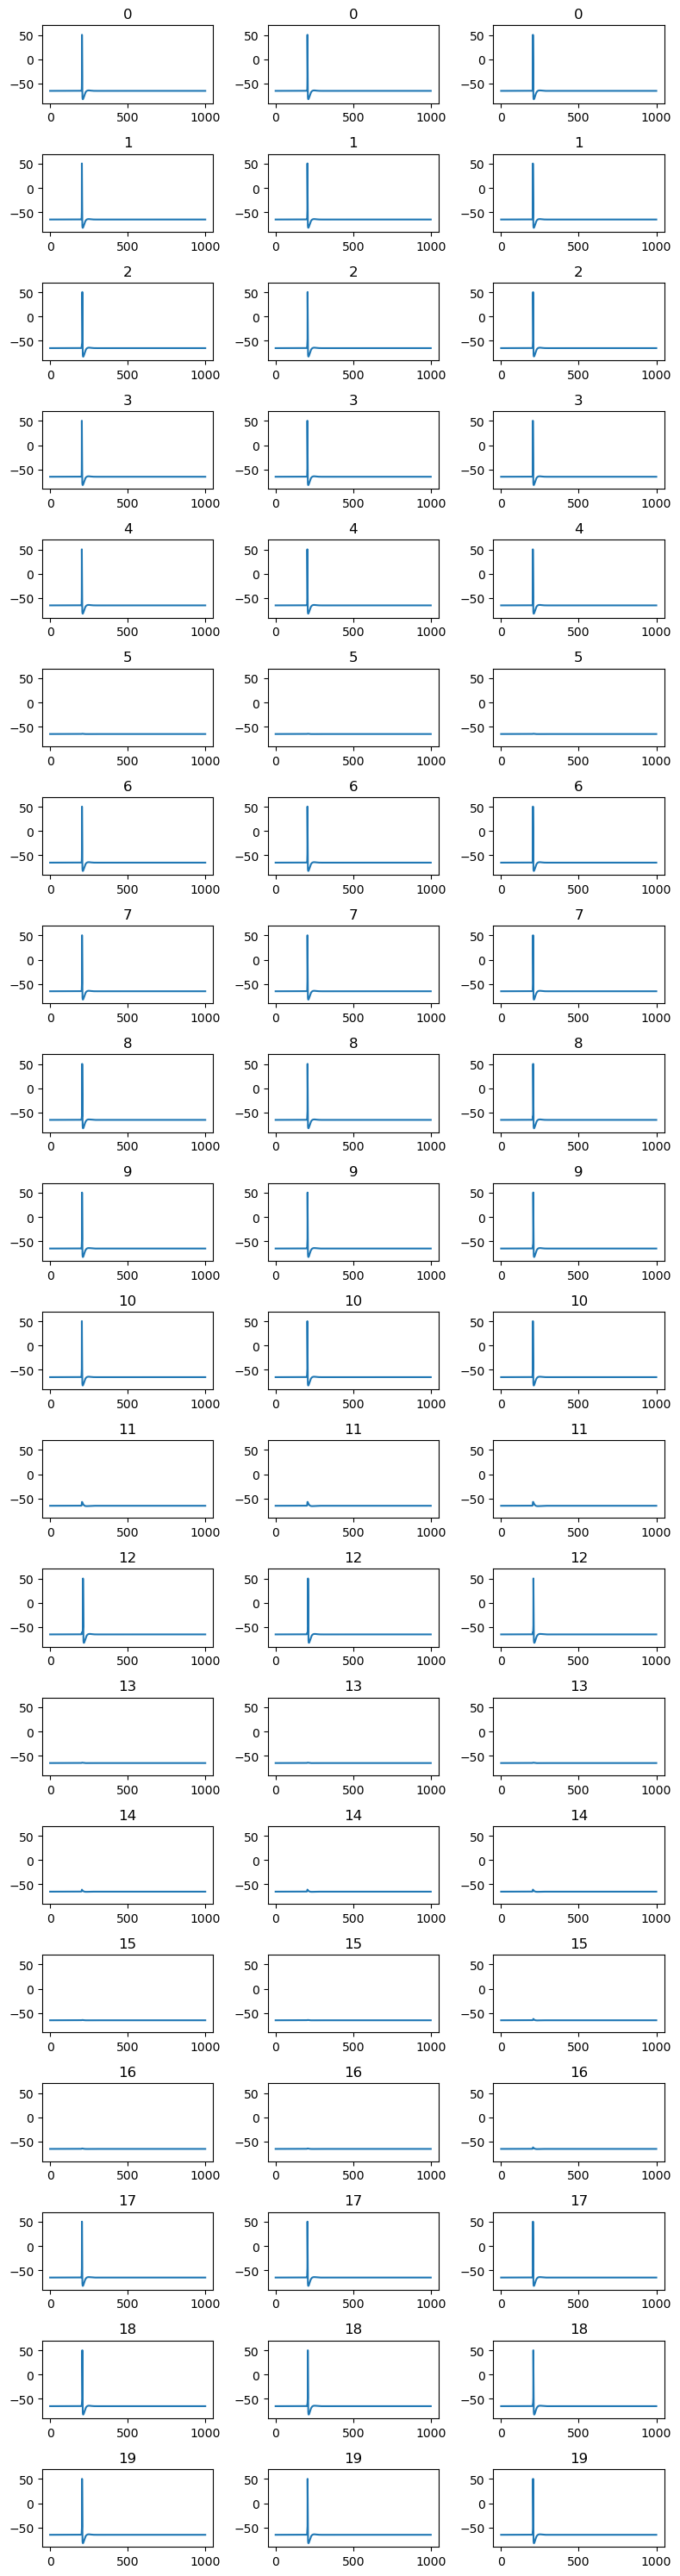

In [4]:
fig, axs = plt.subplots(nrows = 20, ncols = 3, figsize = (8, 30))

for j, stimulation in enumerate(voltages.keys()):
  voltage = voltages[stimulation]
  for i, cell_id in enumerate(np.arange(0, 20)):
    axs[i][j].plot(voltage.index, voltage[cell_id])
    # axs[i][j].set_xlim(180, 250)
    axs[i][j].set_ylim(-90, 70)
    axs[i][j].set_title(cell_id)

plt.tight_layout()
plt.show()

In [5]:
def read_all_frequencies(stimulation):
  cell_ids = np.arange(0, 20)
  frequencies = []
  for cell_id in cell_ids:
    filename = f"../output/temporal-interference-1/{cell_id}/post-stimulation/in-vivo/{stimulation}/spike_times.csv"

    spikes = pd.read_csv(filename, index_col = 0)
    frequency = len(spikes) # / (spikes.Time.max() - spikes.Time.min())
    # frequency = 0 if np.isnan(frequency) else frequency
    frequencies.append(frequency)

  return frequencies

In [6]:
frequencies = {
  "No tTIS": read_all_frequencies("noTI_0.1"),
  "50% tTIS": read_all_frequencies("1000_5_0.5_0.1"),
  "90% tTIS": read_all_frequencies("1000_5_0.9_0.1")
}

No tTIS: 0.7 +- 0.45825756949558394
50% tTIS: 0.7 +- 0.45825756949558394
90% tTIS: 0.7 +- 0.45825756949558394


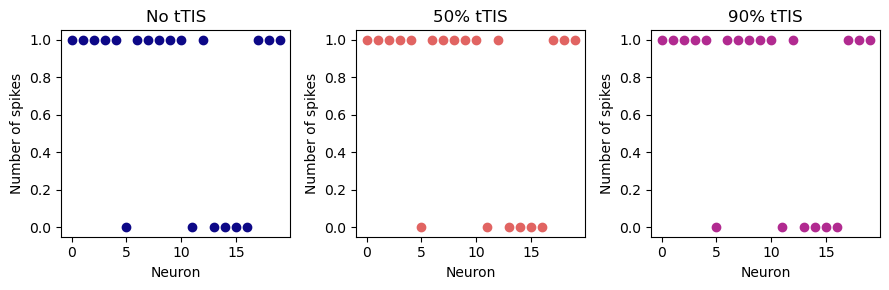

In [7]:
fig, axs = plt.subplots(nrows = 1, ncols = 3, figsize = (9, 3))

for ax, stimulation in zip(axs, frequencies.keys()):
  print(f"{stimulation}: {np.mean(frequencies[stimulation])} +- {np.std(frequencies[stimulation])}")
  ax.scatter(np.arange(0, 20), frequencies[stimulation], color = colors[stimulation])
  ax.set_ylabel("Number of spikes")
  ax.set_title(stimulation)
  ax.set_xlabel("Neuron")

plt.tight_layout()
plt.show()

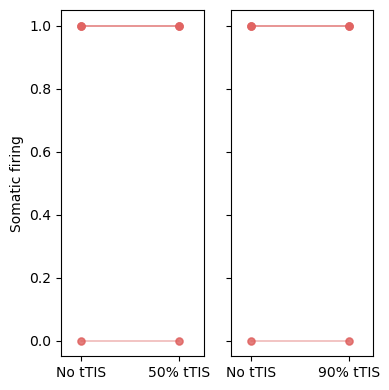

In [8]:
import numpy as np
import matplotlib.pyplot as plt

type = "ltd"
stimulation = "50% tTIS"

fig, axs = plt.subplots(nrows = 1, ncols = 2, figsize = (4, 4), sharey = True)

for ax, stimulation in zip(axs, ["50% tTIS", "90% tTIS"]):
  y1 = frequencies["No tTIS"]
  y2 = frequencies[stimulation]

  x = [False, True]

  for i in range(len(y1)):
    if y1[i] > y2[i]:
      color = colors["No tTIS"]
    else:
      color = colors["50% tTIS"]

    points_x = x
    points_y = [ y1[i], y2[i] ]

    ax.plot(points_x, points_y, color = color, linewidth = 0.1, alpha = 1)
    ax.scatter(points_x, points_y, color=color, s=25, alpha = 0.25)

  ax.set_xticks(x, ["No tTIS", stimulation])
  ax.set_ylabel("Somatic firing")
  ax.set_xlim(-0.2, 1.25)

axs[1].set_ylabel("")
  

plt.tight_layout()
plt.show()

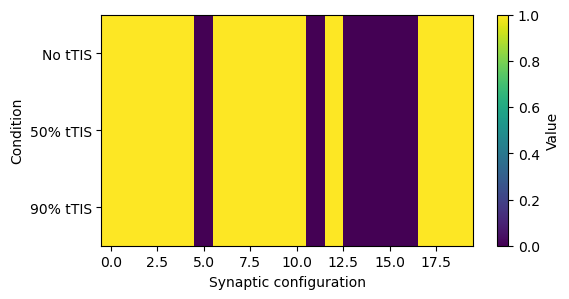

In [9]:
matrix = np.array(list(frequencies.values()))

plt.figure(figsize=(6,3))
plt.imshow(matrix, aspect="auto")
plt.yticks(range(len(frequencies)), list(frequencies.keys()))
plt.colorbar(label="Value")
plt.xlabel("Synaptic configuration")
plt.ylabel("Condition")

plt.show()

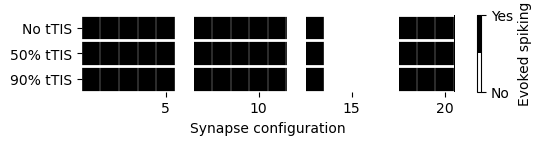

In [10]:
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.colors import ListedColormap

data = frequencies

matrix = np.array(list(data.values())).astype(bool)

cmap = ListedColormap(["white", "black"])

fig, ax = plt.subplots(figsize=(6,1))
im = ax.imshow(matrix, aspect="auto", cmap=cmap, vmin=0, vmax=1)

# integer column indices
ax.set_xticks(np.arange(4, matrix.shape[1], 5))
ax.set_xticklabels(np.arange(0, matrix.shape[1], 5) + 5)

# row labels
ax.set_yticks(np.arange(matrix.shape[0]))
ax.set_yticklabels(list(data.keys()))

# create spacing using gridlines
ax.set_xticks(np.arange(-.5, matrix.shape[1], 1), minor=True)
ax.set_yticks(np.arange(-.5, matrix.shape[0], 1), minor=True)
ax.grid(which="minor", color="white", linestyle="-", linewidth=2, axis = "y")
ax.grid(which="minor", color="white", linestyle="-", linewidth=0.25, axis = "x")
ax.tick_params(which="minor", bottom=False, left=False)

# plt.colorbar(im, ticks=[0,1], label="Evoked spiking")
cbar = plt.colorbar(im, ticks=[0, 1])
cbar.ax.set_yticklabels(["No", "Yes"])
cbar.set_label("Evoked spiking")

for spine in ax.spines.values():
  spine.set_visible(False)

plt.xlabel("Synapse configuration")
plt.ylabel("")
plt.show()

array([ 0,  1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11, 12, 13, 14, 15, 16,
       17, 18, 19])